Project Overview

- This project presents an Exploratory Data Analysis (EDA) on 1,000 retail supermarket transactions to assess departmental sales performance, customer segment behaviors (Member vs. Normal), payment channel adoption, and net revenue generation across product categories.   

- Environment & Tools: Python, Pandas, Matplotlib.   

- Dataset Scope: 1,000 transactions across 12 initial attributes, detailing invoice identifiers, branch locations, customer classifications, gender, product categories, unit prices, purchased quantities, transaction timestamps, payment types, and ratings.   

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [ ]:
data = pd.read_csv("/content/drive/MyDrive/Databaru/supermarket.csv")
data

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,1/29/2019,13:46,Ewallet,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,3/2/2019,17:16,Ewallet,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,2/9/2019,13:22,Cash,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,2/22/2019,15:33,Cash,4.1


Data Cleaning & Feature Engineering

In [ ]:
print(data.columns)
print(data.dtypes)
print(data.isnull().sum())

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Date', 'Time', 'Payment',
       'Rating'],
      dtype='object')
Invoice ID        object
Branch            object
City              object
Customer type     object
Gender            object
Product line      object
Unit price       float64
Quantity           int64
Date              object
Time              object
Payment           object
Rating           float64
dtype: object
Invoice ID       0
Branch           0
City             0
Customer type    0
Gender           0
Product line     0
Unit price       0
Quantity         0
Date             0
Time             0
Payment          0
Rating           0
dtype: int64


In [ ]:
data.drop_duplicates(inplace=True)
print(data.isnull().sum())

Invoice ID       0
Branch           0
City             0
Customer type    0
Gender           0
Product line     0
Unit price       0
Quantity         0
Date             0
Time             0
Payment          0
Rating           0
dtype: int64


In [ ]:
data["Total"] = data["Unit price"] * data["Quantity"]
data["Tax"] = data["Total"] * 0.05
data["Final price"] = data["Total"] - data["Tax"]
data

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating,Total,Tax,Final price
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1,522.83,26.1415,496.6885
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6,76.40,3.8200,72.5800
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4,324.31,16.2155,308.0945
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4,465.76,23.2880,442.4720
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3,604.17,30.2085,573.9615
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,1/29/2019,13:46,Ewallet,6.2,40.35,2.0175,38.3325
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,3/2/2019,17:16,Ewallet,4.4,973.80,48.6900,925.1100
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,2/9/2019,13:22,Cash,7.7,31.84,1.5920,30.2480
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,2/22/2019,15:33,Cash,4.1,65.82,3.2910,62.5290


Missing Value Audit: Initial verification using data.isnull().sum() confirmed zero missing values across all variables.   

Deduplication: Applied data.drop_duplicates(inplace=True) to prevent distorted aggregations. Post-deduplication checks confirmed dataset cleanliness.   

Feature Engineering: Formulated three core financial variables to reflect

commercial store metrics:   

- Total: Gross transaction value calculated via Unit price * Quantity.   

- Tax: Standard 5% value-added tax calculated as Total * 0.05.   

- Final price: Net transaction revenue computed as Total - Tax.   

Exploratory Data Analysis & Key Insights

A. Sales Volume by Category (Best Selling)

             Product line  Quantity
0  Electronic accessories       971
1     Fashion accessories       902
2      Food and beverages       952
3       Health and beauty       854
4      Home and lifestyle       911
5       Sports and travel       920


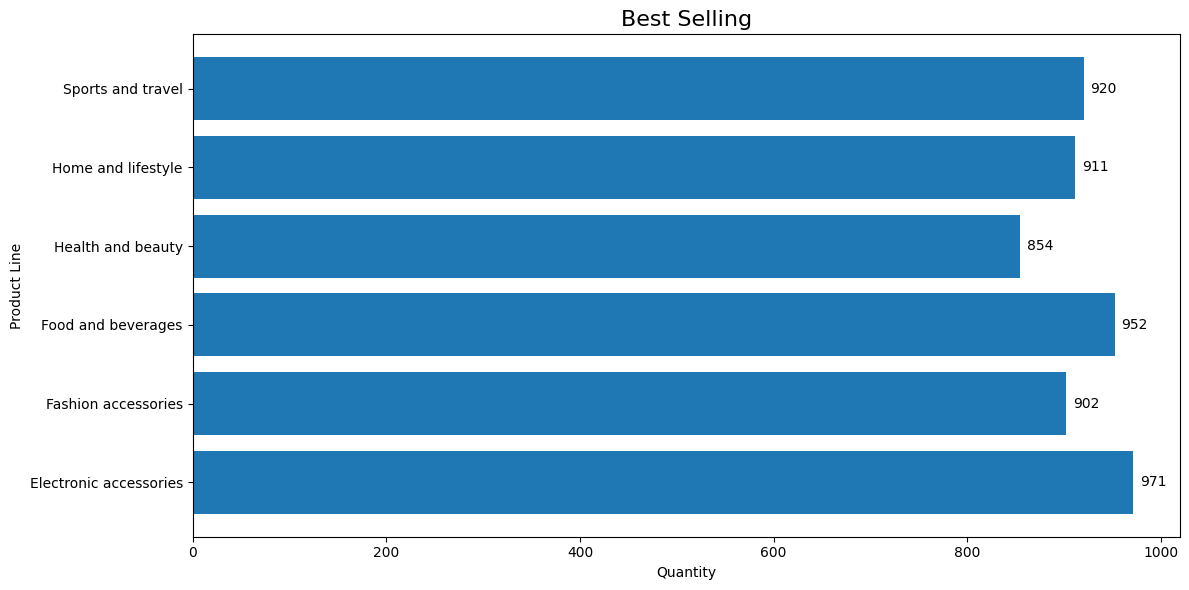

In [ ]:
Product_line = data.groupby("Product line")["Quantity"].sum().reset_index()
print(Product_line)

plt.figure(figsize=(12, 6))
bars = plt.barh(Product_line["Product line"], Product_line["Quantity"])

plt.bar_label(bars, padding=5)
plt.title("Best Selling", fontsize=16)
plt.xlabel("Quantity")
plt.ylabel("Product Line")

plt.tight_layout()
plt.show()

Aggregation of total units sold per product category highlighted consumer demand drivers:   

- Electronic accessories: Generated the highest unit sales volume at 971 units.   

- Food and beverages: Ranked second with 952 units sold.   

- Sports and travel: Followed closely with 920 units.   Home and lifestyle: Accounted for 911 units.   

- Fashion accessories: Contributed 902 units.   

- Health and beauty: Recorded the lowest total unit volume at 854 units.   

B. Customer Segmentation: Normal vs. Member

Comparing transaction counts by membership status identified distinct shopping tendencies between regular shoppers and registered members.

             Product line  Customer type
0  Electronic accessories             92
1     Fashion accessories             92
2      Food and beverages             80
3       Health and beauty             79
4      Home and lifestyle             77
5       Sports and travel             79
             Product line  Customer type
0  Electronic accessories             78
1     Fashion accessories             86
2      Food and beverages             94
3       Health and beauty             73
4      Home and lifestyle             83
5       Sports and travel             87


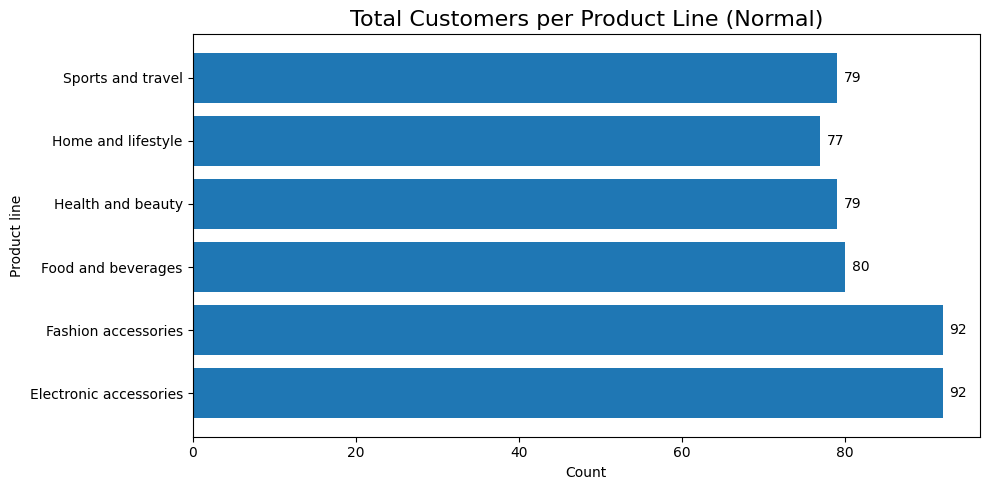

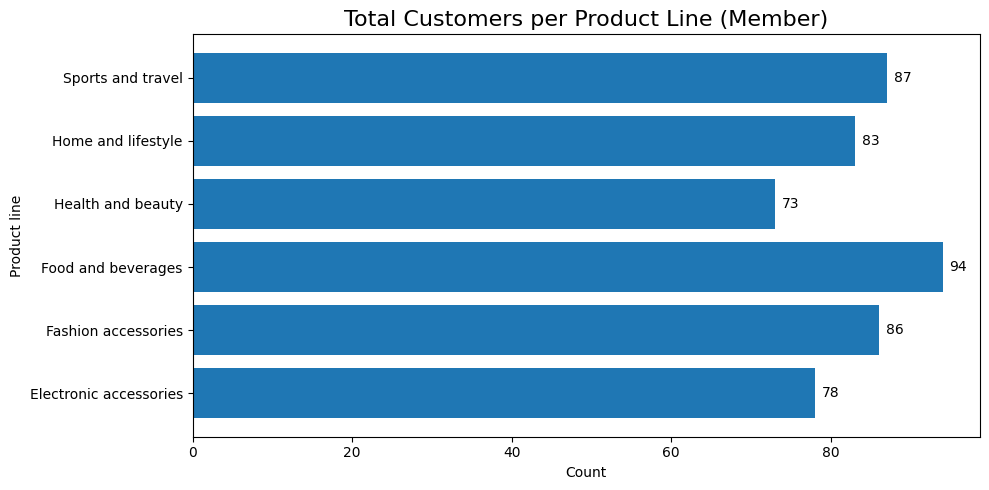

In [ ]:
data_normal = data[data["Customer type"] == "Normal"]
data_member = data[data["Customer type"] == "Member"]

normal = data_normal.groupby("Product line")["Customer type"].count().reset_index()
member = data_member.groupby("Product line")["Customer type"].count().reset_index()

print(normal)
print(member)

# Normal
plt.figure(figsize=(10, 5))
bars_normal = plt.barh(normal["Product line"], normal["Customer type"])

plt.bar_label(bars_normal, padding=5)
plt.title("Total Customers per Product Line (Normal)", fontsize=16)
plt.xlabel("Count")
plt.ylabel("Product line")

plt.tight_layout()
plt.show()

# Member
plt.figure(figsize=(10, 5))
bars_member = plt.barh(member["Product line"], member["Customer type"])

plt.bar_label(bars_member, padding=5)
plt.title("Total Customers per Product Line (Member)", fontsize=16)
plt.xlabel("Count")
plt.ylabel("Product line")

plt.tight_layout()
plt.show()

Normal Customers:

- Highest transaction concentration occurred in Electronic accessories (92 transactions) and Fashion accessories (92 transactions).   

- Other categories: Food and beverages (80 transactions), Health and beauty (79 transactions), Sports and travel (79 transactions), and Home and lifestyle (77 transactions).   

Member Customers:

- Highest purchase frequency centered around essential consumables: Food and beverages (94 transactions) and Sports and travel (87 transactions).   

- Other categories: Fashion accessories (86 transactions), Home and lifestyle (83 transactions), Electronic accessories (78 transactions), and Health and beauty (73 transactions).   

Behavioral Pattern: Registered members exhibit strong repeat engagement with regular consumable categories, while non-members demonstrate heavier engagement with discretionary lifestyle accessories.

C. Payment Method Distribution

       Payment  count
0      Ewallet    345
1         Cash    344
2  Credit card    311


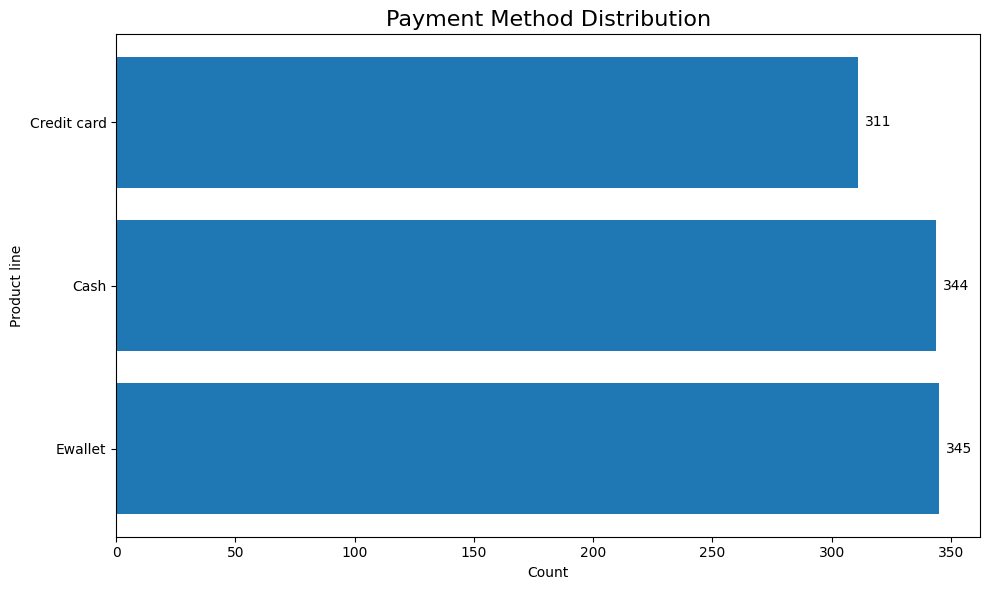

In [ ]:
Payment = data["Payment"].value_counts().reset_index()
print(Payment)

plt.figure(figsize = (10,6))
bars_payment = plt.barh(Payment["Payment"], Payment["count"])

plt.bar_label(bars_payment, padding=5)
plt.title("Payment Method Distribution", fontsize=16)
plt.xlabel("Count")
plt.ylabel("Product line")

plt.tight_layout()
plt.show()

       Payment  count
0      Ewallet    345
1         Cash    344
2  Credit card    311


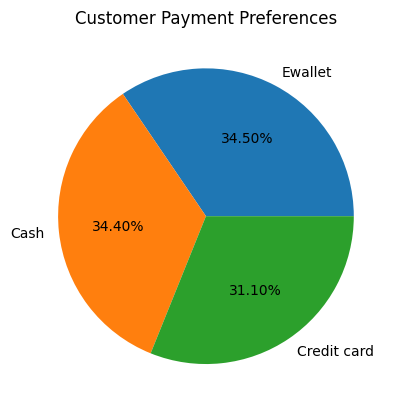

In [ ]:
Percentage = data["Payment"].value_counts().reset_index()
print(Percentage)

plt.pie(Percentage["count"], labels = Percentage["Payment"], autopct = "%1.2f%%")
plt.title("Customer Payment Preferences", fontsize=12)
plt.show()

The transaction distribution across payment methods reveals an evenly balanced adoption between digital and traditional options:
- E-wallet: The most utilized channel with 345 transactions, representing 34.50% of total checkouts.   
- Cash: Placed second with 344 transactions, representing 34.40%.   
- Credit card: Comprised 311 transactions, accounting for 31.10% of purchases.   

D. Departmental Net Revenue Contribution

             Product line  Final price
0  Electronic accessories   49162.5285
1     Fashion accessories   49133.9050
2      Food and beverages   50797.7160
3       Health and beauty   44508.6210
4      Home and lifestyle   48732.2070
5       Sports and travel   49873.0335


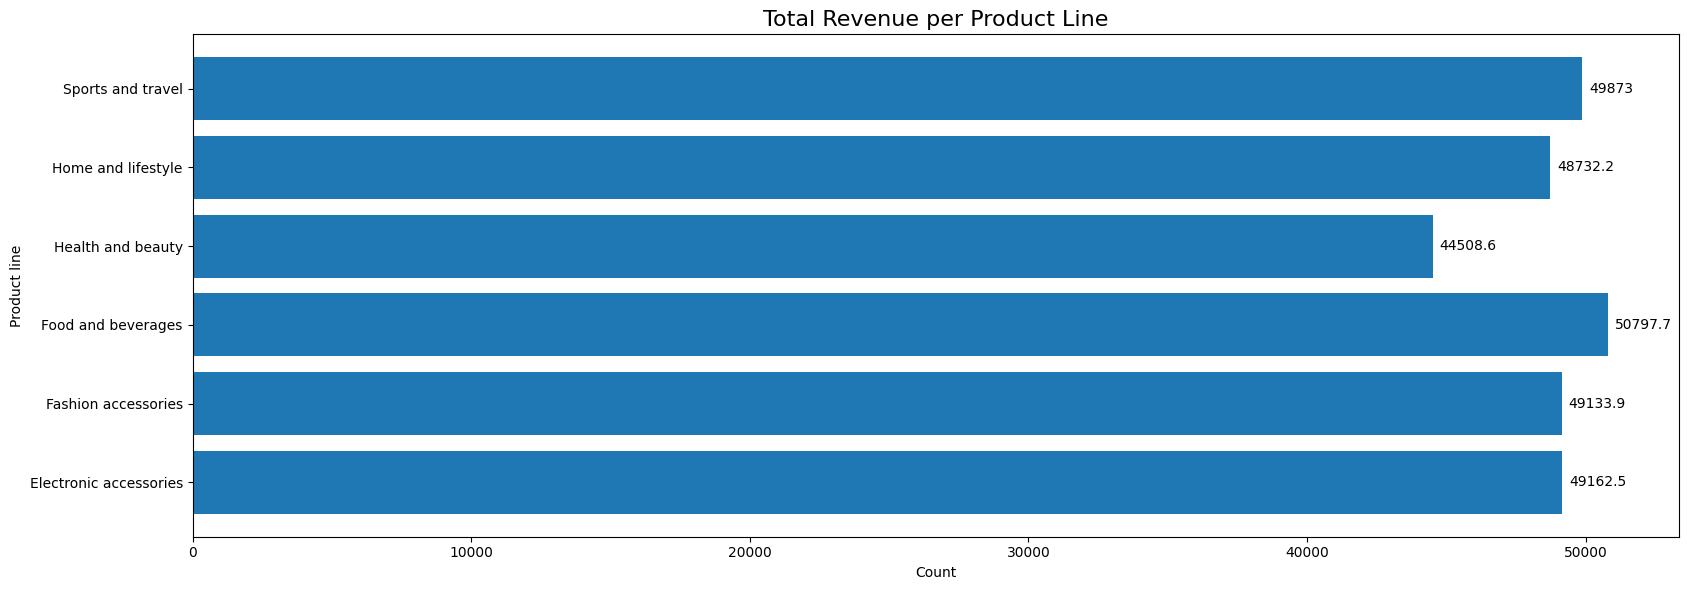

In [ ]:
Product_line = data.groupby("Product line")["Final price"].sum().reset_index()
print(Product_line)

plt.figure(figsize = (17,6))
bars_payment = plt.barh(Product_line["Product line"], Product_line["Final price"])

plt.bar_label(bars_payment, padding=5)
plt.title("Total Revenue per Product Line", fontsize=16)
plt.xlabel("Count")
plt.ylabel("Product line")

plt.tight_layout()
plt.show()

Aggregating total net revenue (Final price) illustrated that category sales volume does not directly correlate with total monetary yield:   
- Food and beverages: Generated the highest total net revenue at $50,797.72.

- Sports and travel: Ranked second in financial yield with $49,873.83.

- Electronic accessories: Placed third at $49,162.53 despite leading in total unit volume.   

- Fashion accessories: Contributed $49,133.91.

- Home and lifestyle: Accounted for $48,732.21.  

- Health and beauty: Generated the lowest revenue across all departments at $44,508.62.   

Strategic Business Recommendations :

- Strengthen Member Loyalty Programs for Consumables:
Because member customers engage most heavily in Food and Beverages, introducing targeted point multipliers or bundled subscription rewards for staple grocery items will drive higher customer retention and basket value.

- Leverage Digital Wallet Partnerships:
With E-wallets leading the checkout share (34.50%), partnering with top digital payment providers for co-funded cashback campaigns will accelerate digital transactions and lower operational cash-handling costs.   

- Product Cross-Selling in Electronics:
While Electronic Accessories boasts the highest unit velocity (971 units), it trails Food and Beverages in net revenue. Creating bundle deals with higher-margin auxiliary products will capture greater revenue per transaction.   

- Merchandising Review for Health & Beauty:
As the lowest performer in both unit sales (854 units) and net revenue ($44,508.62), this department warrants a catalogue rationalization and revised shelf placement to boost product turnover.   